**AUTOENCODERS 2D ATTN**

In [3]:
import digitalhub as dh
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [4]:
job_name = "v2"                                    
dataset = "Standard" 
sensor = "OPT"    

n_channels = 2 if sensor == "SAR" else 10 # OPT

parameters = {
    "job_name": job_name,
    "dataset": dataset,
    "sensor": sensor,
    "ltae": True,
    "spac_net": False,
    "resume": False,
    "time_debug": False,
    
    "epochs": 200, 
    "batch_size": 16, 
    "lr": 1e-4, 
    "weight_decay": 1e-4,      
    "patch_size": 256, 
    "n_images": 4, 
    "n_channels": n_channels,                                            
    "num_channels_latent_space": 16,                                                                                             
    "workers": 0,
    "job_name": job_name,
    "dataset": dataset,
    "patience": 10,                                    
    "min_delta": 1e-4,                             
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",      
        "spec": {"size": "500Gi"}   
    }
]

**BUILD ENVIRONMENT**

In [5]:
autoencoder_attn_train_func = project.new_function(
    name=f'cae_attn_opt',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="autoencoders:train_autoencoder_attn",
    image="harbor.atlas.fbk.eu/rsde/rsde-platform-floods-floodsimagev3:9b7e2",
)

**TRAINING**

In [ ]:
resources = {"cpu": "4", "mem": "60Gi"}

run_ad = autoencoder_attn_train_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    resources = resources,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run cae: {run_ad.id}")

2026-10-23 15:13:07,331 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:12,339 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:17,349 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:22,357 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:27,366 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:32,374 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15:13:37,384 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 15351678deff44c38a999e8bbe4f1737 to finish...
2026-10-23 15

**PLOTS**

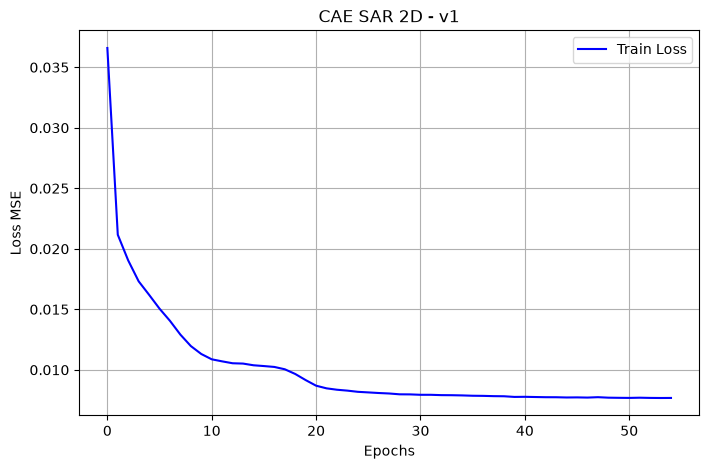

In [ ]:
path = project.get_artifact(f"autoencoder_attn_{sensor}_metrics_{job_name}").download(overwrite=True)
df = pd.read_csv(path)

plt.figure(figsize=(8, 5))
plt.plot(df['epoch'], df['train_loss'], color='blue', label='Train Loss')
plt.title(f'CAE {sensor} 2D - {job_name}')
plt.xlabel('Epochs')
plt.ylabel('Loss MSE')
plt.grid(True)
plt.legend()
plt.show()